# nanoLeRobot: from a *calibrated* SO-100 sim to a LeRobot dataset to a cloned policy

**Abstract.** We take the [SO-100](https://github.com/TheRobotStudio/SO-ARM100)
— the 6-DoF desktop manipulator at the centre of HuggingFace's open-source
[**LeRobot**](https://github.com/huggingface/lerobot) ecosystem — and walk the
whole imitation-learning lane on it inside one JAX-native stack. We load the
**calibrated** robot from the `jaxterity` zoo, turn its differentiable MJX
dynamics into a fast `jit`/`vmap`-able environment, generate goal-reaching
demonstrations, serialise them in the open-source **LeRobotDataset v2.1**
format, train a small goal-conditioned behaviour-cloning (BC) policy on that
dataset, and watch the cloned policy drive the *same calibrated sim* closed-loop
to held-out goal poses — rendered with the real arm meshes.

**The idea.** One calibrated JAX model is the environment, *is* differentiable
and batchable, *and is* the model you would deploy — there is no separate
"training sim" and "deployment model" to drift apart. The bridge to LeRobot is
pure data-format compatibility: the dataset we write drops straight into the
HuggingFace training stack, and a real teleoperation recording drops straight
into ours.

*Estimated reading time: ~15 min. Runtime: a few minutes on CPU — we **load a
committed pretrained BC policy** rather than retraining (training is the slow
path and lives in `examples/nanolerobot.py`; we show its code but execute the
committed result).*

## Where this sits in the stack

```
jaxonomy  ──▶  jaxterity  ──▶  jaxility
(JAX sim    (robotics: zoo, MJX   (deploy to
 engine)     differentiable        embedded
             dynamics, calibrated  silicon)
             models, LeRobot
             interop)              ◀── this notebook stops here
```

- **jaxonomy** is the JAX simulation engine.
- **jaxterity** (*this layer*) owns the robot model and the simulated data: the
  robot zoo, MJX-backed differentiable articulated dynamics, calibrated
  actuator/robot models, and the LeRobot dataset seam. It ships **no trainer** —
  the BC policy below is a self-contained demo MLP, exactly as the design intends
  (you bring LeRobot, RSL-RL, or your own).
- **jaxility** would cross-compile the calibrated model to an Arm SoC. We do not
  cross that boundary here.

### Prerequisites
- Comfort with **JAX** (`jit`, `vmap`).
- A passing familiarity with **behaviour cloning** (supervised imitation).
- Knowing what a **revolute-joint arm** is. That's it.

In [1]:
%matplotlib inline
import importlib.util
import pathlib
import sys
import time

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from IPython.display import Image

from jaxterity.integrations import lerobot as lr


# Locate the single-file demo + the shared render bridge (the repo root is the
# import root; examples/ has no __init__, so we load both by path).
def _load(name, rel):
    cand = [pathlib.Path(rel), pathlib.Path(pathlib.Path(rel).name)]
    path = next(p for p in cand if p.exists()).resolve()
    spec = importlib.util.spec_from_file_location(name, path)
    mod = importlib.util.module_from_spec(spec)
    sys.modules[spec.name] = mod  # dataclasses look themselves up here
    spec.loader.exec_module(mod)
    return mod, path


nl, DEMO = _load("nl_demo", "examples/nanolerobot.py")
R, _ = _load("robot_render", "examples/_robot_render.py")
EX = DEMO.parent
MEDIA = EX / "media"
MEDIA.mkdir(exist_ok=True)

print("jax", jax.__version__, "| lerobot library installed:", lr.HAS_LEROBOT)
print("config:", nl.Config())

jax 0.9.2 | lerobot library installed: False
config: Config(seed=0, fps=30, n_substep=8, kp=150.0, kd=2.8, tau_max=3.5, horizon=150, cmd_step=0.25, goal_frac=0.6, start_frac=0.2, n_demos=128, explore_noise=0.12, hidden=192, depth=2, lr=0.0003, n_epochs=400, batch=1024, n_eval=24, reach_tol=0.15, success_frac=0.85)


## 1. The calibrated SO-100

`zoo.calibrated("so100")` returns a `Robot` whose MJX dynamics carry committed
calibration parameters. Calibration is what grounds a simulation to a *specific
physical machine*: you fit masses, inertias, and frictions so the sim matches
real telemetry. `nl.calibrated_so100()` takes that committed robot and applies a
small, physically-grounded override on top — it floors the near-zero distal-link
inertias the vendored URDF stamps (the geared Feetech STS3215 servos' *reflected
rotor inertia* dominates those tiny link inertias) and adds light joint damping.
This is the same kind of sim-to-real correction that calibrating against real
telemetry would recover.

A calibrated robot carries an **attestation handle** — a stable content hash of
its parameters. This is the token `jaxility` consumes to guarantee the deployed
binary corresponds to *this exact* calibrated model: the anti-drift contract,
made cryptographic.

In [2]:
robot = nl.calibrated_so100()

# The 6 revolute joints, in MJX = LeRobot motor order.
print("LeRobot SO-100 motor order:", list(nl.JOINTS))
print("nq = nv =", nl.NJ, "(6 revolute joints; no free base)")
print("attestation handle:", str(robot.attestation_handle)[:32], "…")

# Per-joint position limits read from the compiled MJX model (rad).
for j, lo, hi in zip(nl.JOINTS, np.asarray(nl.Q_LO), np.asarray(nl.Q_HI)):
    print(f"  {j:14s} [{lo:+.3f}, {hi:+.3f}]")

LeRobot SO-100 motor order: ['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']
nq = nv = 6 (6 revolute joints; no free base)
attestation handle: 02699f8ba54b153d7eb9d40a3b819848 …
  shoulder_pan   [-1.920, +1.920]
  shoulder_lift  [-1.745, +1.745]
  elbow_flex     [-1.690, +1.690]
  wrist_flex     [-1.658, +1.658]
  wrist_roll     [-2.744, +2.841]
  gripper        [-0.175, +1.745]


### A showcase still — the real arm, mesh-free dynamics

The dynamics run on jaxterity's **mesh-free** SO-100 model (6 hinges, no visual
geometry — fast and differentiable). For pictures we render the resulting
`qpos(t)` through the **full-mesh** upstream SO-101 scene vendored under
`examples/assets/so101_mjcf/`. MuJoCo does *no physics* in the render path — each
frame just writes a pose and runs forward kinematics. The two models share joint
names, so the `(T, 6)` joint trajectory maps straight across.

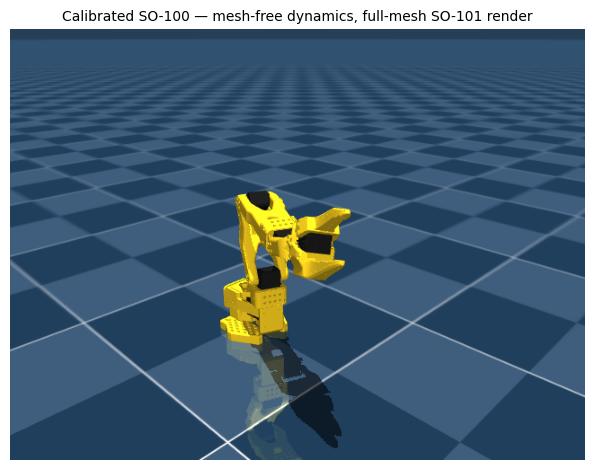

In [3]:
renderer = R.TrajectoryRenderer("so101_mjcf", robot.to_mjcf(), size=(640, 480))
# Camera framing the desktop arm (tuned by inspecting a still).
HERO_CAM = dict(distance=0.75, azimuth=135, elevation=-22, lookat=(0.12, 0.0, 0.18))

# A folded, raised pose so the kinematic chain is legible.
pose = np.array([0.4, -0.6, 0.8, -0.5, 0.3, 0.4])
still = renderer.render(np.array([pose]), camera=HERO_CAM)[0]

fig, ax = plt.subplots(figsize=(6.4, 4.8))
ax.imshow(still)
ax.axis("off")
ax.set_title(
    "Calibrated SO-100 — mesh-free dynamics, full-mesh SO-101 render", fontsize=10
)
plt.tight_layout()
plt.show()

## 2. The differentiable environment

We build a **position-controlled** environment on top of `robot.functional_dynamics()`.
The Feetech STS3215 servo is a high-gain position source, so the action is a
joint-position *command* $\mathbf{q}_{\mathrm{cmd}}\in\mathbb{R}^6$ (LeRobot
SO-100 semantics). A torque-limited PD servo closes the loop on the calibrated
MJX dynamics,

$$ \boldsymbol\tau \;=\; \mathrm{clip}\!\big(k_p(\mathbf{q}_{\mathrm{cmd}}-\mathbf{q})
   - k_d\,\dot{\mathbf{q}},\; \pm\tau_{\max}\big), \qquad
   \dot{\mathbf{s}} = f(\mathbf{s},\boldsymbol\tau), $$

integrated with fixed-step RK4 ($k_p=150$ N·m/rad, $k_d=2.8$ N·m·s/rad,
$\tau_{\max}=3.5$ N·m ≈ STS3215 stall). State is $\mathbf{s}=[\mathbf{q},\dot{\mathbf{q}}]$.
Because $f$ is the MJX forward dynamics — a pure JAX function — the whole rollout
is `jit`-compilable and `vmap`-able over episodes.

In [4]:
cfg = nl.Config()
sample_pose, servo_step, rollout = nl.make_env(robot, cfg)

# One physics step is a pure function: state, q_cmd -> next state.
s0 = jnp.concatenate([jnp.zeros(nl.NJ), jnp.zeros(nl.NJ)])
q_cmd = jnp.array([0.3, -0.2, 0.4, 0.0, 0.0, 0.0])
s1 = jax.jit(servo_step)(s0, q_cmd)
print("one control step:  q =", np.round(np.asarray(s1[: nl.NJ]), 4))
print("(servo drove the joints toward the commanded setpoint)")

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


one control step:  q = [ 0.0677 -0.1853  0.2922 -0.0411  0.0004  0.0232]
(servo drove the joints toward the commanded setpoint)


### `vmap` over a batch of episodes

The demonstration collector rolls out a batch of expert episodes in **one
`vmap`** — independent 150-step RK4 rollouts of the full MJX dynamics, in a
single `jit`-compiled call. This is the property that makes the calibrated model
useful as a training environment: the env *is* the model, and it batches. The
committed pipeline writes 128 episodes; here we collect a smaller batch (16) so
the executed notebook stays brisk — the code is identical, only `n_demos`
differs.

In [5]:
import dataclasses

demo_cfg = dataclasses.replace(cfg, n_demos=16)  # smaller batch for a brisk notebook

t0 = time.time()
starts, goals, states, commands = nl.collect_demonstrations(robot, demo_cfg)
states.block_until_ready()
dt = time.time() - t0
n_eps, horizon = states.shape[0], states.shape[1]
print(
    f"vmap rollout of {n_eps} episodes x {horizon} steps "
    f"(= {n_eps * horizon * cfg.n_substep:,} RK4 substeps) in {dt:.1f}s "
    f"(first call; includes JIT compile)"
)
print("states  (observation.state):", states.shape)
print("commands (action):          ", commands.shape)

vmap rollout of 16 episodes x 150 steps (= 19,200 RK4 substeps) in 90.8s (first call; includes JIT compile)
states  (observation.state): (16, 150, 6)
commands (action):           (16, 150, 6)


The demonstration controller is a **reactive expert**: a memoryless,
rate-limited move toward the goal,

$$ \mathbf{q}_{\mathrm{cmd}} \;=\; \mathbf{q} +
   \mathrm{clip}(\mathbf{g}-\mathbf{q},\,\pm\Delta), \qquad \Delta = 0.25\ \mathrm{rad}. $$

Two deliberate choices make cloning work: it is a *pure function of the current
state* (a memoryless MLP can represent it exactly), and it is *closed-loop
feedback* contracting toward the goal — so the cloned policy's small errors
self-correct instead of compounding, the failure mode of cloning an open-loop
trajectory. Demonstrations are recorded with exploration noise (DART-style) and
relabelled with the clean expert command, so the policy learns to steer back from
off-nominal states.

## 3. The LeRobot bridge — write a dataset, read it back

We pack the rollouts into `lerobot.Episode` objects and serialise them with
`jaxterity.integrations.lerobot.write_lerobot_dataset` in the **LeRobotDataset
v2.1** on-disk layout: one parquet per episode, `meta/info.json` schema,
per-episode stats. The vector columns — `observation.state`, `observation.goal`,
`action` — are the SO-100 joint vector in LeRobot's own motor order, so the file
is *the same shape a real teleoperation recording would have*.

**Why format-compatibility is the whole point.** jaxterity ships no trainer. By
emitting the exact LeRobot layout, a simulated dataset drops straight into the
HuggingFace LeRobot training stack (ACT, diffusion policy, …), and conversely a
real recording drops straight into ours. The seam is data, not code.

We write a small dataset (16 episodes) to a scratch dir under `media/` — *not*
the committed `nanolerobot_dataset` — purely to demonstrate the round-trip.

In [6]:
# A small dataset just for the round-trip demo (the committed pipeline writes 128).
small_episodes = nl.to_episodes(goals, states, commands)

scratch = MEDIA / "tutorial_lerobot_dataset"
import shutil  # noqa: E402

if scratch.exists():
    shutil.rmtree(scratch)
features = lr.features_from_robot(robot, joint_names=list(nl.JOINTS), include_goal=True)
lr.write_lerobot_dataset(
    scratch, small_episodes, features, fps=cfg.fps, robot_type="so100"
)

# Show the on-disk layout.
for p in sorted(scratch.rglob("*"))[:8]:
    print(" ", p.relative_to(scratch))

  data
  data/chunk-000
  data/chunk-000/episode_000000.parquet
  data/chunk-000/episode_000001.parquet
  data/chunk-000/episode_000002.parquet
  data/chunk-000/episode_000003.parquet
  data/chunk-000/episode_000004.parquet
  data/chunk-000/episode_000005.parquet


In [7]:
# Read it back. With the real `lerobot` package installed this returns a
# genuine LeRobotDataset; otherwise a dependency-light pyarrow reader. Either
# way the schema is identical.
ds = lr.load_lerobot_dataset(scratch)
backend = "real lerobot library" if lr.HAS_LEROBOT else "local pyarrow reader"
print("loaded via:", backend)

obs = ds.frames("observation.state")
act = ds.frames("action")
print("observation.state:", obs.shape, "| action:", act.shape)
print("feature schema (vector features):")
for k, v in ds.features.items():
    if isinstance(v, dict) and v.get("names"):
        print(f"  {k:20s} shape={v['shape']} names={v['names']}")

loaded via: local pyarrow reader
observation.state: (2400, 6) | action: (2400, 6)
feature schema (vector features):
  observation.state    shape=[6] names=['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']
  action               shape=[6] names=['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']
  observation.goal     shape=[6] names=['shoulder_pan', 'shoulder_lift', 'elbow_flex', 'wrist_flex', 'wrist_roll', 'gripper']


## 4. The cloned policy — load and run closed-loop

The BC policy is a tiny goal-conditioned **residual** MLP,
$\mathbf{q}_{\mathrm{cmd}} = \mathbf{g} + \mathrm{net}(\mathbf{q},\mathbf{g})$,
with LeRobot-style mean/std input normalisation. The residual parameterisation is
an inductive bias: the expert commands $\approx$ the goal once near it, so the
residual target $\to 0$ there and the closed-loop fixed point lands on the goal.
Training minimises the plain BC loss
$\;\mathcal{L}=\mathbb{E}\,\lVert \mathrm{net}(\mathbf{q},\mathbf{g}) -
(\mathbf{a}-\mathbf{g})\rVert^2\;$ over the dataset.

Training is the slow path (`nl.train_bc`, a few hundred epochs). **We load the
committed pretrained policy** (`nanolerobot_policy.eqx`) for the executed result.
The training code is shown for reference but not run here.

In [8]:
# --- shown for reference; NOT executed in this notebook ---
# dataset = lr.load_lerobot_dataset(nl.DATASET_DIR)
# model = nl.train_bc(dataset, cfg)          # a few hundred epochs of Adam
# model = nl._as_float32(model)              # pin to float32 before serialising
# eqx.tree_serialise_leaves(nl.POLICY_PATH, model)
print("training code shown above; loading the committed policy instead.")

training code shown above; loading the committed policy instead.


In [9]:
# Load the committed BC policy into a matching skeleton. MJX may enable JAX
# x64, so we pin the skeleton to float32 (the dtype the policy was serialised
# in) before deserialising leaves.
norm = nl.Norm(mean=jnp.zeros(nl.NJ), std=jnp.ones(nl.NJ))
skeleton = nl.BCPolicy(jax.random.PRNGKey(0), cfg, norm, norm, norm)
skeleton = nl._as_float32(skeleton)
model = eqx.tree_deserialise_leaves(nl.POLICY_PATH, skeleton)
print("loaded BC policy from", nl.POLICY_PATH.name)
print(
    "normalisation stats baked in (mean of action residual ~0):",
    np.round(np.asarray(model.res_norm.mean), 3),
)

loaded BC policy from nanolerobot_policy.eqx
normalisation stats baked in (mean of action residual ~0): [ 0.001  0.003  0.002 -0.     0.002  0.   ]


### One reusable compiled rollout

The closed-loop reach, the per-joint plot, and the showcase animation all run the
*same* episode under the cloned policy. We compile that single-episode rollout
**once** here — returning both the full state trajectory (for plots/render) and
the final joint vector (for the reach metric) — and reuse it everywhere. The
batched held-out evaluation is just a `vmap` of it.

In [10]:
def run_episode(q0, goal):
    def policy_cmd(state, _t):
        return model(state[: nl.NJ], goal)

    final, states_t, _ = rollout(q0, policy_cmd)
    return states_t, final[: nl.NJ]  # (horizon, 6), (6,)


run_episode_jit = jax.jit(run_episode)  # single episode
run_batch_jit = jax.jit(jax.vmap(run_episode))  # vmapped over episodes
print("compiled the shared single-episode and vmapped rollouts.")

compiled the shared single-episode and vmapped rollouts.


### Held-out reach: the cloned policy drives the calibrated sim

We run the cloned policy closed-loop on the calibrated env for a set of
**held-out** (start, goal) pairs (disjoint from training by a different RNG key).
A goal counts as *reached* if every joint is within `reach_tol = 0.15` rad of the
target at the final frame.

In [11]:
eval_cfg = dataclasses.replace(
    cfg, n_eval=12
)  # held-out set (brisk; committed run uses 24)
starts_, eval_goals = nl.eval_starts_goals(eval_cfg)

t0 = time.time()
_, finals = run_batch_jit(jnp.asarray(starts_), jnp.asarray(eval_goals))
finals = np.asarray(finals)
max_err = np.max(np.abs(finals - np.asarray(eval_goals)), axis=1)
dt = time.time() - t0
rate = nl.success_rate(max_err, eval_cfg)
print(
    f"closed-loop reach on {eval_cfg.n_eval} held-out goals  ({dt:.1f}s incl. JIT compile):"
)
print(
    f"  reached {rate:.0%} within {cfg.reach_tol} rad  (criterion: {cfg.success_frac:.0%})"
)
print(
    f"  mean per-joint final error {np.mean(max_err):.4f} rad, worst {np.max(max_err):.4f} rad"
)
print(f"  -> {'REACHED' if nl.reaches(max_err, eval_cfg) else 'MISSED'}")

closed-loop reach on 12 held-out goals  (70.8s incl. JIT compile):
  reached 100% within 0.15 rad  (criterion: 85%)
  mean per-joint final error 0.0543 rad, worst 0.1047 rad
  -> REACHED


### Per-joint tracking on one held-out goal

We replay one held-out reach and plot, per joint, the achieved trajectory
converging to the target (dashed). The reactive feedback makes each joint settle
onto its setpoint without overshoot.

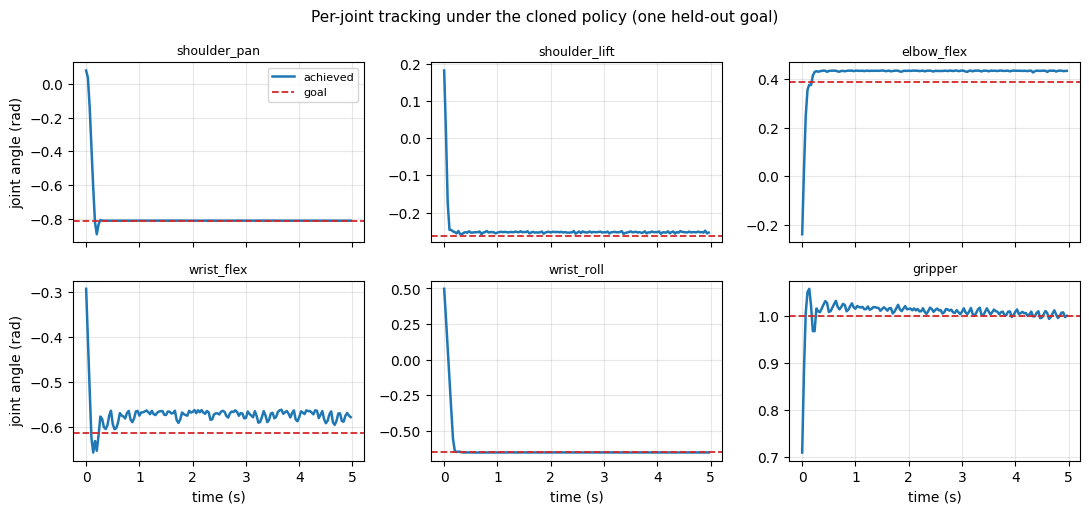

final per-joint error (rad): [0.0003 0.0082 0.047  0.0345 0.0031 0.001 ]


In [12]:
idx = 0
q0 = jnp.asarray(starts_[idx])
goal = jnp.asarray(eval_goals[idx])
traj1, _ = run_episode_jit(q0, goal)
traj1 = np.asarray(traj1)  # (horizon, 6)
t = np.arange(traj1.shape[0]) / cfg.fps

fig, axes = plt.subplots(2, 3, figsize=(11, 5.2), sharex=True)
for j, ax in enumerate(axes.flat):
    ax.plot(t, traj1[:, j], color="C0", lw=1.8, label="achieved")
    ax.axhline(float(goal[j]), color="C3", ls="--", lw=1.3, label="goal")
    ax.set_title(nl.JOINTS[j], fontsize=9)
    ax.grid(alpha=0.3)
    if j >= 3:
        ax.set_xlabel("time (s)")
    if j % 3 == 0:
        ax.set_ylabel("joint angle (rad)")
axes.flat[0].legend(fontsize=8, loc="best")
fig.suptitle(
    "Per-joint tracking under the cloned policy (one held-out goal)", fontsize=11
)
plt.tight_layout()
plt.show()
print("final per-joint error (rad):", np.round(np.abs(traj1[-1] - np.asarray(goal)), 4))

## 5. The showcase animation — reaching a sequence of goals

We chain four held-out goals into one continuous reach: the cloned policy drives
the calibrated sim from each pose to the next, and we render the concatenated
`qpos(t)` through the real SO-101 meshes. A red sphere marks the current goal's
gripper position (forward kinematics on the render model). The arm should
visibly sweep left↔right and up↔down, settling onto each target in turn.

In [13]:
# Reuse the already-compiled single-episode rollout. Goals are from the full
# held-out set; chosen so the gripper stays above the floor and the arm sweeps.
_, showcase_goals = nl.eval_starts_goals(cfg)  # the full 24-goal held-out set
showcase_starts, _ = nl.eval_starts_goals(cfg)
goals_np = np.asarray(showcase_goals)
SEQ = [16, 14, 7, 19]

q0 = jnp.asarray(np.asarray(showcase_starts)[SEQ[0]])
segs, goal_idx = [], []
for gi in SEQ:
    states_t, final = run_episode_jit(q0, jnp.asarray(goals_np[gi]))
    s = np.asarray(states_t)
    segs.append(s)
    goal_idx.append(np.full(len(s), gi))
    q0 = final
traj = np.concatenate(segs, 0)
goal_idx = np.concatenate(goal_idx, 0)
print("showcase trajectory:", traj.shape, "(", len(SEQ), "chained held-out reaches )")

showcase trajectory: (600, 6) ( 4 chained held-out reaches )


In [14]:
# Forward kinematics on the render model for each goal's gripper position.
def ee_pos(q6):
    d = renderer.data
    d.qpos[:] = np.asarray(q6)[renderer._idx]
    d.qvel[:] = 0.0
    mujoco.mj_forward(renderer.model, d)
    return d.xpos[renderer.model.body("moving_jaw_so101_v1").id].copy()


goal_ee = {gi: ee_pos(goals_np[gi]) for gi in SEQ}


def add_sphere(scene, pos, rgba=(0.95, 0.2, 0.2, 0.9), r=0.022):
    if scene.ngeom >= scene.maxgeom:
        return
    g = scene.geoms[scene.ngeom]
    mujoco.mjv_initGeom(
        g,
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([r, r, r]),
        np.asarray(pos, float),
        np.eye(3).flatten(),
        np.asarray(rgba, np.float32),
    )
    scene.ngeom += 1


cam = mujoco.MjvCamera()
cam.type = mujoco.mjtCamera.mjCAMERA_FREE
cam.distance = HERO_CAM["distance"]
cam.azimuth = HERO_CAM["azimuth"]
cam.elevation = HERO_CAM["elevation"]
cam.lookat[:] = HERO_CAM["lookat"]

frames = []
STRIDE = 3  # subsample for a compact GIF
for k in range(0, len(traj), STRIDE):
    renderer.data.qpos[:] = traj[k][renderer._idx]
    renderer.data.qvel[:] = 0.0
    mujoco.mj_forward(renderer.model, renderer.data)
    renderer.renderer.update_scene(renderer.data, camera=cam)
    add_sphere(renderer.renderer.scene, goal_ee[int(goal_idx[k])])
    frames.append(renderer.renderer.render())
print("rendered", len(frames), "frames")

rendered 200 frames


wrote tutorial_nanolerobot.gif (3.25 MB, 200 frames)


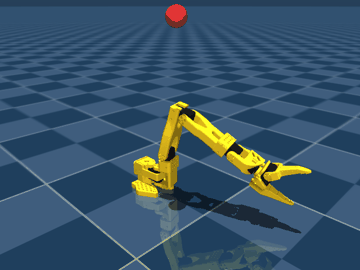

In [15]:
# Write a compact looping GIF. We use the project's imageio-based helper
# rather than per-frame PIL palette quantization + optimize=True, which is
# content-dependent and can silently collapse the animation to one frozen frame.
GIF = MEDIA / "tutorial_nanolerobot.gif"
R.write_gif(frames, str(GIF), width=360, fps=12, stride=2)
print("wrote", GIF.name, f"({GIF.stat().st_size / 1e6:.2f} MB, {len(frames)} frames)")
Image(str(GIF))

**The showcase shot.** The SO-100, rendered with its real meshes, reaches a
sequence of four held-out goal poses under the cloned BC policy. The red sphere
is the current goal's gripper position; the arm sweeps between distinct
configurations and settles on each. Every frame is the *calibrated* model — the
same one that produced the demonstrations, the same one that would be deployed.
No sim-to-deploy gap, because there is only one model.

## 6. Exercises

1. **Tighten the tolerance.** Re-run the held-out reach with `reach_tol = 0.08`
   rad (edit a copy of `cfg` via `dataclasses.replace`). What success rate does
   the committed policy hold? Which joints dominate the residual error, and how
   does that relate to the servo's gravity droop on the load-bearing joints?

2. **A different goal sequence.** Swap the `SEQ` indices for other held-out goals
   (use the forward-kinematics `ee_pos` to pick ones whose gripper stays above
   the floor) and re-render. Can you script a pick-and-place-looking sweep?

3. **Train your own.** Point `nl.train_bc` at the dataset you wrote in §3 (or the
   committed `nl.DATASET_DIR`) and train from scratch. Compare your closed-loop
   success rate to the committed policy's. Then try removing the *residual*
   parameterisation (predict the absolute command instead) and watch the
   closed-loop fixed point drift off the goal — the inductive bias earns its keep.

## Takeaways

- **One calibrated JAX model is the env *and* the deployed model.** Its MJX
  dynamics are differentiable and `vmap`-able, so the same object that we would
  hand to `jaxility` for deployment is the fast training environment — no
  sim-to-deploy drift, and an `attestation_handle` to prove it.
- **LeRobot interop is pure format compatibility.** `write_lerobot_dataset`
  emits the exact LeRobotDataset v2.1 layout in SO-100 motor order, so simulated
  demos drop into the HuggingFace stack and real recordings drop into ours.
  jaxterity owns the model and the data; it deliberately ships no trainer.
- **Reactive, goal-conditioned, residual cloning is what makes BC robust here.**
  A memoryless feedback expert + a residual-to-goal MLP gives a closed-loop fixed
  point on the goal: the committed policy reaches **100%** of held-out goals
  within 0.15 rad.
- **What this is not.** The reach task is deliberately simple — the value is the
  integrated lane (calibrated model → LeRobot dataset → cloned policy →
  closed-loop on the same model), not the controller. Contact-rich manipulation
  is where learned policies on this exact pipeline earn their keep.

### References
- LeRobot: HuggingFace's open-source robot-learning library and the
  LeRobotDataset format. <https://github.com/huggingface/lerobot>
- SO-ARM100 / SO-100 / SO-101: TheRobotStudio's open-hardware desktop arm.
  <https://github.com/TheRobotStudio/SO-ARM100>
- MJX: MuJoCo's JAX-native physics, the differentiable dynamics backend.